# Financify: ML pipeline, step by step

Financify answers two questions for a person saving towards a goal in an Indonesian city:

1. **How much will prices rise next month in my city?** A model forecasts next month's headline inflation (month-to-month).
2. **What does inflation do to my savings goal?** A planner grows the goal's cost with inflation and estimates the time to reach it.

This notebook walks through the ML part (1) and ends with how its output feeds the planner (2).
It calls the same functions as `train.py` (`src/`), so the numbers match `artifacts/metrics/metrics.json`.
It never writes artifacts; run `python train.py` for that.

In [1]:
import os, sys
from pathlib import Path

# run from the repo root whether the notebook is opened from notebooks/ or the root
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import MIN_VALID_MONTHS, clean, combine, coverage_report, load_bps, load_raw, overlap_check, validate
from src.features import FEATURE_GROUPS, build_features, columns
from src.models import BASELINES, CANDIDATES, metrics
from src.pihps import load_monthly
from src.split import VAL_YEARS, folds, split
from train import cv_score

pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 110

## 1. Inflation data (BPS)

Two sources, merged per city-month:
- a legacy BPS export for 2008–2016 (`data/raw/inflasi_v3.csv`)
- the official BPS WebAPI from 2017 onwards (`data/raw/bps/`)

Placeholder values (CPI = 0 before a city joined the survey, or a 0% that contradicts a moving CPI) become missing instead of a fake 0%.

In [2]:
legacy, bps = clean(load_raw()), load_bps()
full = combine(legacy, bps)
quality = validate(full)
print("legacy vs BPS API, overlapping months:", overlap_check(legacy, bps))
{k: v for k, v in quality.items() if k not in ("outliers", "cities_below_min_history")}

legacy vs BPS API, overlapping months: {'rows': 6806, 'share_equal': 0.9999, 'max_abs_diff': 0.04}


{'rows': 21078,
 'cities': 150,
 'date_range': ['2008-01', '2026-09'],
 'placeholder_rows_set_to_missing': 1224,
 'missing_inflation_rows': 1224,
 'outlier_rows': 170}

In [3]:
cov = coverage_report(full)
keep = cov.loc[cov["observation_count"] >= MIN_VALID_MONTHS, "city"]
panel = full[full["city"].isin(keep)].reset_index(drop=True)
print(f"{len(keep)} of {cov.shape[0]} cities have >= {MIN_VALID_MONTHS} valid months and are modelled")
cov.sort_values("observation_count").head()

82 of 150 cities have >= 96 valid months and are modelled


,city,first_valid_date,last_valid_date,observation_count,missing_months,invalid_zero_count
31,KAB BANDUNG,2024-01,2026-09,33,0,0
30,KAB BADUNG,2024-01,2026-09,33,0,0
29,KAB ACEH TENGAH,2024-01,2026-09,33,0,0
28,KAB ACEH TAMIANG,2024-01,2026-09,33,0,0
59,KAB MALUKU TENGAH,2024-01,2026-09,33,0,0


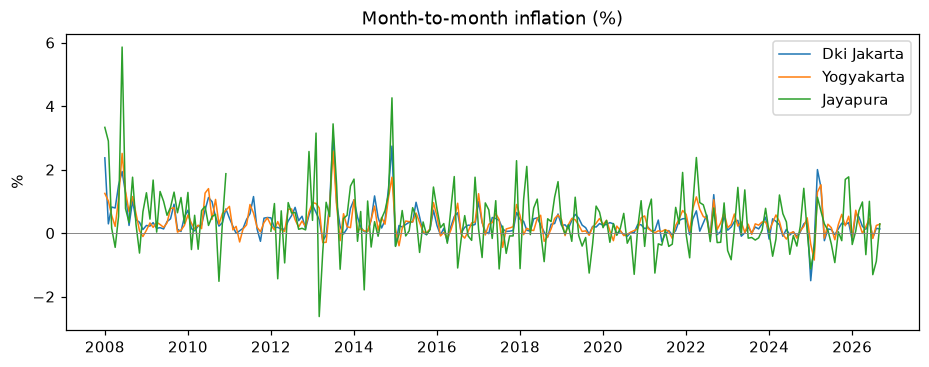

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for city in ["DKI JAKARTA", "YOGYAKARTA", "JAYAPURA"]:
    s = panel[panel["city"] == city].set_index("date")["inflation_mtm"]
    ax.plot(s.index, s, label=city.title(), lw=1)
ax.axhline(0, color="grey", lw=.6)
ax.set(title="Month-to-month inflation (%)", ylabel="%")
ax.legend();

## 2. Food prices (Bank Indonesia PIHPS)

Daily traditional-market prices for 10 commodities, scraped per regency (`download.py pihps`).
For each city-month we keep:
- the **monthly mean** price (missing if fewer than 10 priced days)
- the mean of the **first 5 priced days**, used for the nowcast (available around the 8th of each month)

In [5]:
prices = load_monthly(keep)
print(prices.shape, "| from", prices["date"].min().date(), "to", prices["date"].max().date())
prices.tail(3)

(9165, 22) | from 2017-07-01 to 2026-10-01


,city,date,beef,bird_chili,chicken,chili,cooking_oil,egg,garlic,rice,...,beef_first,bird_chili_first,chicken_first,chili_first,cooking_oil_first,egg_first,garlic_first,rice_first,shallot_first,sugar_first
9162,YOGYAKARTA,2026-08-01,159400.0,47754.761905,40273.809524,38176.190476,22759.523810,24595.238095,43047.619048,14471.428571,...,159400.0,45890.0,37700.0,37600.0,22750.0,24500.0,44000.0,14450.0,40500.0,18400.0
9163,YOGYAKARTA,2026-09-01,159400.0,57190.909091,40931.818182,42972.727273,22840.909091,25554.545455,42750.000000,14781.818182,...,159400.0,54130.0,41350.0,34510.0,22810.0,25250.0,42750.0,14720.0,37500.0,18450.0
9164,YOGYAKARTA,2026-10-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,159400.0,62530.0,39600.0,53780.0,22850.0,25700.0,42750.0,14800.0,37500.0,18540.0


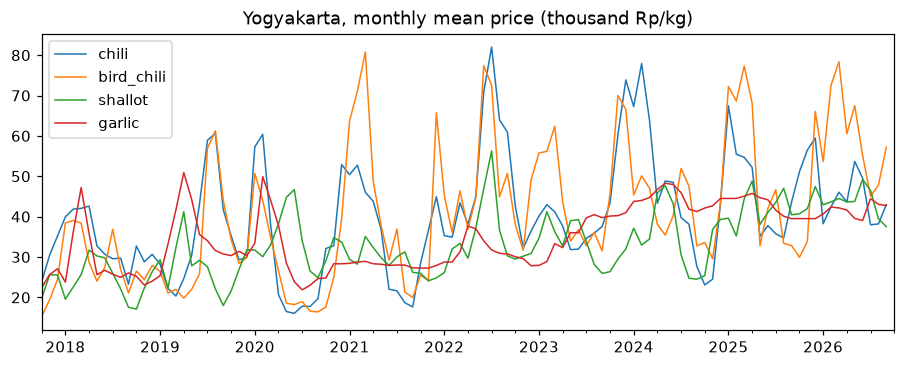

In [6]:
p = prices[prices["city"] == "YOGYAKARTA"].set_index("date")
fig, ax = plt.subplots(figsize=(10, 3.5))
(p[["chili", "bird_chili", "shallot", "garlic"]] / 1000).plot(ax=ax, lw=1)
ax.set(title="Yogyakarta, monthly mean price (thousand Rp/kg)", xlabel="");

## 3. Features

All features describe what is known at the forecast origin, month `t`; the target is inflation in month `t+1`.
Windows are built per city, so a city's features never use another city's data.

The food groups fill a missing value with 0 (no change) and set a per-group `*_missing` flag. This keeps rows from before 2017 (no PIHPS yet) in training.

In [7]:
for group, cols in FEATURE_GROUPS.items():
    print(f"{group:18s} {len(cols):2d}  {cols[:4]}{' ...' if len(cols) > 4 else ''}")

lags               12  ['inflation_mtm', 'inflation_lag_1', 'inflation_lag_2', 'inflation_lag_3'] ...
rolling             4  ['inflation_roll_3', 'inflation_roll_6', 'inflation_roll_12', 'inflation_std_12']
seasonality         3  ['month_sin', 'month_cos', 'year_end_flag']
islamic_calendar    2  ['ramadan_flag', 'eid_fitr_flag']
food_prices         6  ['rice_price_mom', 'chicken_price_mom', 'egg_price_mom', 'shallot_price_mom'] ...
food_prices_extra   6  ['beef_price_mom', 'garlic_price_mom', 'bird_chili_price_mom', 'cooking_oil_price_mom'] ...
food_nowcast       11  ['rice_nowcast', 'chicken_nowcast', 'egg_nowcast', 'shallot_nowcast'] ...


In [8]:
feats = build_features(panel, prices).dropna(subset=columns(FEATURE_GROUPS))
feats[feats["city"] == "YOGYAKARTA"][["date", "target_date", "inflation_mtm", "chili_price_mom",
                                      "chili_nowcast", "food_nowcast_missing", "eid_fitr_flag", "target_inflation"]].tail(4)

,date,target_date,inflation_mtm,chili_price_mom,chili_nowcast,food_nowcast_missing,eid_fitr_flag,target_inflation
18446,2026-06-01,2026-07-01,0.46,-7.788521,-23.191919,0,0,-0.17
18447,2026-07-01,2026-08-01,-0.17,-23.254282,-1.024320,0,0,0.24
18448,2026-08-01,2026-09-01,0.24,0.492404,-9.603343,0,0,0.28
18449,2026-09-01,2026-10-01,0.28,12.564210,25.149143,0,0,NaN


## 4. Split: rolling-origin validation + untouched test

- **Validation:** 4 folds, one per year 2021–2024. Each fold trains on every earlier target month and scores that year. Feature groups and the model are chosen on the pooled MAE of all 4 folds.
- **Test:** target months from 2025-01 onwards. It is used once, after selection.

In [9]:
dev, test = split(feats)
cv = folds(dev)
for year, tr, va in cv:
    print(f"fold {year}: train {len(tr):6d} rows (targets to {tr['target_date'].max():%Y-%m}) | validate {len(va)} rows")
print(f"test: {len(test)} rows, {test['target_date'].min():%Y-%m} to {test['target_date'].max():%Y-%m}")

fold 2021: train  10512 rows (targets to 2020-12) | validate 984 rows
fold 2022: train  11496 rows (targets to 2021-12) | validate 984 rows
fold 2023: train  12480 rows (targets to 2022-12) | validate 984 rows
fold 2024: train  13464 rows (targets to 2023-12) | validate 984 rows
test: 1722 rows, 2025-01 to 2026-09


## 5. Baselines and feature-group ablation

Baselines: *naive* (next month = this month) and *seasonal naive* (next month = same month last year).
Candidates: Ridge regression and histogram gradient boosting.

Greedy forward selection: start from the lags, add one group at a time, keep it only if pooled validation MAE goes down. MAE is in percentage points (pp) of month-to-month inflation.

In [10]:
cv_val = pd.concat([va for _, _, va in cv])
pd.DataFrame({name: metrics(cv_val["target_inflation"], f(cv_val)) for name, f in BASELINES.items()}).T

,mae,rmse,n
naive,0.4707,0.6730,3936.0
seasonal_naive,0.4708,0.6259,3936.0


In [11]:
rows, selected_groups, best_score = [], {}, {}
for name in CANDIDATES:
    groups = ["lags"]
    best = cv_score(name, columns(groups), cv)
    rows.append({"model": name, "step": "lags", "mae": best["mae"], **best["mae_by_year"], "kept": True})
    for grp in [g for g in FEATURE_GROUPS if g != "lags"]:
        score = cv_score(name, columns(groups + [grp]), cv)
        kept = score["mae"] < best["mae"]
        rows.append({"model": name, "step": "+ " + grp, "mae": score["mae"], **score["mae_by_year"], "kept": kept})
        if kept:
            groups, best = groups + [grp], score
    selected_groups[name], best_score[name] = groups, best["mae"]
ablation = pd.DataFrame(rows)
ablation

,model,step,mae,2021,2022,2023,2024,kept
0,ridge,lags,0.3798,0.3092,0.5638,0.2945,0.3518,True
1,ridge,+ rolling,0.3799,0.3101,0.5639,0.2945,0.3511,False
2,ridge,+ seasonality,0.3814,0.2995,0.5711,0.3038,0.3511,False
3,ridge,+ islamic_calendar,0.3759,0.3221,0.5414,0.3053,0.3348,True
4,ridge,+ food_prices,0.3620,0.2827,0.5838,0.2797,0.3017,True
5,ridge,+ food_prices_extra,0.3626,0.2835,0.5834,0.2814,0.3021,False
6,ridge,+ food_nowcast,0.3275,0.2627,0.5037,0.2596,0.2840,True
7,hist_gbr,lags,0.3811,0.2895,0.6063,0.2967,0.3318,True
8,hist_gbr,+ rolling,0.3824,0.2859,0.6120,0.2999,0.3316,False
9,hist_gbr,+ seasonality,0.3690,0.2763,0.5615,0.2868,0.3512,True


In [12]:
selected = min(best_score, key=best_score.get)
print("validation MAE:", best_score)
print("selected model:", selected, "| groups:", selected_groups[selected])

validation MAE: {'ridge': 0.3275, 'hist_gbr': 0.3267}
selected model: hist_gbr | groups: ['lags', 'seasonality', 'islamic_calendar', 'food_prices', 'food_nowcast']


## 6. Test (2025 onwards, used once)

Each candidate is refitted on all validation-period rows with its selected groups, then scored on test.

In [13]:
preds = test[["city", "target_date", "target_inflation"]].copy()
for name, f in BASELINES.items():
    preds[name] = f(test)
for name in CANDIDATES:
    cols = columns(selected_groups[name])
    preds[name] = CANDIDATES[name]().fit(dev[cols], dev["target_inflation"]).predict(test[cols])
models = [*BASELINES, *CANDIDATES]
result = pd.DataFrame({m: metrics(preds["target_inflation"], preds[m]) for m in models}).T
result["vs_naive"] = (1 - result["mae"] / result.loc["naive", "mae"]).map("{:.0%}".format)
result

,mae,rmse,n,vs_naive
naive,0.6942,0.9532,1722.0,0%
seasonal_naive,0.6851,0.8917,1722.0,1%
ridge,0.4221,0.5931,1722.0,39%
hist_gbr,0.4377,0.6187,1722.0,37%


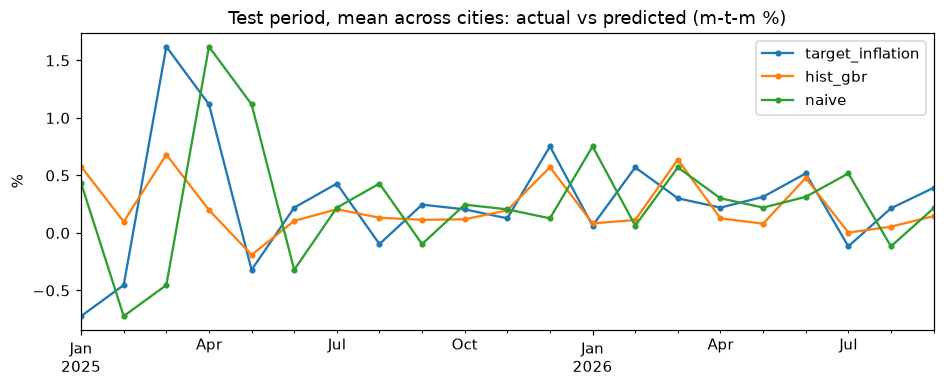

In [14]:
monthly = preds.groupby("target_date")[["target_inflation", selected, "naive"]].mean()
fig, ax = plt.subplots(figsize=(10, 3.5))
monthly.plot(ax=ax, marker="o", ms=3)
ax.set(title="Test period, mean across cities: actual vs predicted (m-t-m %)", xlabel="", ylabel="%");

In [15]:
abs_err = preds[models].sub(preds["target_inflation"], axis=0).abs()
by_city = abs_err.groupby(preds["city"]).mean().sort_values(selected)
print("easiest cities"); display(by_city.head(3).round(3))
print("hardest cities"); display(by_city.tail(3).round(3))

easiest cities


,naive,seasonal_naive,ridge,hist_gbr
city,,,,
BATAM,0.421,0.392,0.285,0.242
SINGKAWANG,0.474,0.428,0.222,0.261
SEMARANG,0.493,0.523,0.292,0.274


hardest cities


,naive,seasonal_naive,ridge,hist_gbr
city,,,,
MANOKWARI,1.467,1.219,0.921,0.888
TERNATE,1.525,1.266,0.934,0.893
BAU-BAU,1.356,1.234,0.946,0.925


## 7. From forecast to the savings plan

The app serves the model saved by `train.py` (`artifacts/model.joblib`, refitted on every labeled month).
The one-month forecast tells the user the **direction** of prices. The planner uses a **long-term** rate instead: the city's compounded inflation over the last 12 months (the user can override it). A one-month forecast is too noisy to compound over years.

In [16]:
from src.inference import Forecaster
from src.financial import plan

fc = Forecaster()
f = fc.forecast("Yogyakarta")
annual, as_of = fc.trailing_annual_inflation("Yogyakarta")
print(f"{f['city']}: {f['as_of']} actual {f['previous_inflation']}% -> {f['forecast_period']} forecast "
      f"{f['predicted_inflation']}% ({f['trend']}), model {f['model']}")
print(f"last 12 months, compounded: {annual}%")
plan(current_savings=15_000_000, monthly_income=10_000_000, monthly_expenses=6_000_000,
     goal_amount=100_000_000, annual_inflation_pct=annual)

YOGYAKARTA: 2026-09 actual 0.28% -> 2026-10 forecast 0.28% (unchanged), model hist_gbr
last 12 months, compounded: 3.3%


{'goal_today': 100000000,
 'inflation_adjusted_goal': 106420579,
 'monthly_saving_capacity': 4000000,
 'months_to_goal': 23,
 'time_to_goal': {'years': 1, 'months': 11},
 'annual_inflation_assumption_pct': 3.3,
 'note': 'Planning estimate, not financial advice. Assumes constant income, expenses and inflation, and no investment return.'}